# 08 · Background distribution of mutational distances

**Question.** Is an embedding distance of a given size *large* or just *typical*? The distances of notebook 03
have no reference scale and are not comparable between models (ESM-2, ProtT5 and Ankh embeddings have very
different norms). This notebook builds a **background (null) distribution** with unrelated proteins:

1. Randomly sample proteins from a large FASTA file (UniRef) — no specific motif.
2. In each protein pick a random **18-residue peptide** and embed it **in the context of the full sequence**
   (same procedure as notebook 03).
3. Replace each of the 14 central positions (2–15), one at a time, by a **random different amino acid**.
4. Compute the distance between the mutant and the wild-type peptide embeddings: local `d_p` (mutated
   position) and global `D` (Frobenius norm). Distances are also expressed **relative to the norm of the WT
   embedding** (`d_p / ||e_WT,p||`, `D / ||E_WT||_F`) so that models can be compared.
5. Look at the distribution of the distances for each model.

**Part B** (optional) places the observed LxCxE mutations (notebook 03) in this background, per model and
position (percentile): *near 50 = as large as a random substitution; above 95 = unusually large.*

**Efficiency.** Each window needs one forward pass per model: the WT and its 14 mutants have the same length, so
they are processed together as a single batch. The FASTA file is read in one pass (reservoir sampling) and only
valid sequences are kept.

**Inputs:** a FASTA file of background proteins (`BACKGROUND_FASTA`); for Part B also
`mutant_embedding_distances.csv`, `wt_embeddings.npz` and `df_tp.csv` (notebooks 01 and 03).
**Outputs:** `data/processed/background_distances.csv`, `results/background_*.csv` and figures.

> **Hardware.** GPU required.

In [ ]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Project paths
#   * Locally: start Jupyter from the `notebooks/` folder.
#   * Google Colab: Google Drive is mounted; edit the folder name below so it
#     points to the project folder stored in your Drive.
#   * Anywhere: set the PROJECT_DIR environment variable to override.
# ---------------------------------------------------------------------------
try:
    from google.colab import drive

    drive.mount("/content/drive")
    DEFAULT_PROJECT_DIR = Path("/content/drive/MyDrive/SLiMs_Project")
except ImportError:
    DEFAULT_PROJECT_DIR = Path.cwd().parent

PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", DEFAULT_PROJECT_DIR))
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
for folder in (PROCESSED_DIR, RESULTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def save_figure(name):
    """Save the current matplotlib figure into figures/ (call before plt.show())."""
    plt.savefig(FIGURES_DIR / name, dpi=300, bbox_inches="tight")

import gc
import re

import seaborn as sns
import torch
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer, T5EncoderModel, T5Tokenizer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cuda


## 1. Configuration

In [ ]:
# FASTA with background proteins (e.g. a UniRef100 download). Put it in data/raw/ and set the file name here.
BACKGROUND_FASTA = RAW_DIR / "uniref_identity_1_0_AND_taxonomy_id_2026_10_06.fasta"

# `start_offset` = number of special tokens the tokenizer puts BEFORE the first residue.
#   * ESM-2 prepends <cls>                          -> 1
#   * T5-style tokenizers (ProtT5, Ankh) only append </s> at the end -> 0
# The extraction function checks the token count, so a wrong value fails loudly.
EMBEDDING_MODELS = {
    "ESM-2 (650M)": {"hf_id": "facebook/esm2_t33_650M_UR50D", "start_offset": 1, "dim": 1280},
    "ProtT5": {"hf_id": "Rostlab/prot_t5_xl_uniref50", "start_offset": 0, "dim": 1024},
    "Ankh": {"hf_id": "ElnaggarLab/ankh-base", "start_offset": 0, "dim": 768},
}

N_SEQUENCES = 1000        # proteins sampled -> 14 background distances per protein and model
MIN_LENGTH, MAX_LENGTH = 18, 1000   # accepted protein lengths (long proteins need much more GPU memory)
WINDOW_LENGTH = 18
MUTATED_POSITIONS = list(range(2, 16))  # 1-based positions inside the peptide (14 central ones)
CORE_POSITIONS = (5, 7, 9)              # L, C, E of the LxCxE motif (used only in Part B)
BATCH_SIZE = 16           # sequences per forward pass (WT + 14 mutants = 15 fit in one batch)
AMINO_ACIDS = list("ACDEFGHIKLMNPQRSTVWY")
RNG_SEED = 42

In [ ]:
def load_embedding_model(model_name):
    """Load one pLM and return `embed(sequences, peptide_start, peptide_length)`.

    `sequences` is a list of strings of EQUAL length (e.g. the WT and all its mutants). The result has shape
    (n_sequences, peptide_length, embedding_dim). Sequences are processed in mini-batches of BATCH_SIZE.
    """
    cfg = EMBEDDING_MODELS[model_name]
    hf_id, start_offset = cfg["hf_id"], cfg["start_offset"]

    if model_name.startswith("ESM-2"):
        tokenizer = AutoTokenizer.from_pretrained(hf_id)
        model = AutoModel.from_pretrained(hf_id).to(device).eval()

        def encode(chunk):
            return tokenizer(chunk, return_tensors="pt", padding=True)

    elif model_name == "ProtT5":
        tokenizer = T5Tokenizer.from_pretrained(hf_id, do_lower_case=False)
        dtype = torch.float16 if torch.cuda.is_available() else torch.float32
        model = T5EncoderModel.from_pretrained(hf_id, torch_dtype=dtype).to(device).eval()

        def encode(chunk):
            # ProtT5 expects space-separated residues; rare amino acids -> X
            spaced = [" ".join(re.sub(r"[UZOB]", "X", s)) for s in chunk]
            return tokenizer(spaced, return_tensors="pt", padding=True)

    elif model_name == "Ankh":
        tokenizer = AutoTokenizer.from_pretrained(hf_id)
        model = T5EncoderModel.from_pretrained(hf_id).to(device).eval()

        def encode(chunk):
            # Character-level vocabulary: one token per residue + </s> (ids built directly, see notebook 03)
            ids = [tokenizer.convert_tokens_to_ids(list(s)) + [tokenizer.eos_token_id] for s in chunk]
            if any(tokenizer.unk_token_id in row for row in ids):
                raise ValueError("Some residues are not in the Ankh vocabulary (got <unk>).")
            return {
                "input_ids": torch.tensor(ids),
                "attention_mask": torch.ones(len(ids), len(ids[0]), dtype=torch.long),
            }

    else:
        raise ValueError(f"Unknown model: {model_name}")

    @torch.no_grad()
    def embed(sequences, peptide_start, peptide_length):
        length = len(sequences[0])
        if any(len(s) != length for s in sequences):
            raise ValueError("All sequences in a batch must have the same length.")
        expected_tokens = length + start_offset + 1  # + end-of-sequence token
        first = start_offset + peptide_start

        parts = []
        for i in range(0, len(sequences), BATCH_SIZE):
            inputs = {name: value.to(device) for name, value in encode(sequences[i:i + BATCH_SIZE]).items()}
            hidden = model(**inputs).last_hidden_state  # (batch, n_tokens, dim)
            if hidden.shape[1] != expected_tokens:
                raise ValueError(
                    f"{model_name}: got {hidden.shape[1]} tokens for {length} residues "
                    f"(expected {expected_tokens}). Check `start_offset` in EMBEDDING_MODELS."
                )
            parts.append(hidden[:, first:first + peptide_length, :].float().cpu().numpy())
        return np.concatenate(parts)

    return embed

## 2. Sample proteins and plan the mutations

The random peptides and substitutions are drawn **once**, so every model is evaluated on exactly the same
mutations.

In [ ]:
def iter_fasta(path):
    """Yield (id, sequence) pairs from a FASTA file without loading it into memory."""
    header, parts = None, []
    with open(path) as handle:
        for line in handle:
            line = line.strip()
            if line.startswith(">"):
                if header is not None:
                    yield header, "".join(parts)
                header, parts = line[1:].split()[0], []
            elif line:
                parts.append(line)
    if header is not None:
        yield header, "".join(parts)


def sample_fasta(path, n_sequences, rng):
    """Uniform random sample of valid sequences in a single pass (reservoir sampling)."""
    standard = set(AMINO_ACIDS)
    reservoir, n_valid = [], 0
    for seq_id, sequence in iter_fasta(path):
        if not MIN_LENGTH <= len(sequence) <= MAX_LENGTH or not set(sequence) <= standard:
            continue  # wrong length or non-standard residues (X, B, Z, U, ...)
        n_valid += 1
        if len(reservoir) < n_sequences:
            reservoir.append((seq_id, sequence))
        else:
            j = int(rng.integers(0, n_valid))
            if j < n_sequences:
                reservoir[j] = (seq_id, sequence)
    return reservoir, n_valid


if not BACKGROUND_FASTA.exists():
    raise FileNotFoundError(f"Background FASTA not found: {BACKGROUND_FASTA} (see data/README.md)")

rng = np.random.default_rng(RNG_SEED)
sampled, n_valid = sample_fasta(BACKGROUND_FASTA, N_SEQUENCES, rng)
print(f"{n_valid} valid sequences in the file; {len(sampled)} sampled")

209601 valid sequences in the file; 1000 sampled


In [ ]:
windows = []
for seq_id, sequence in sampled:
    start = int(rng.integers(0, len(sequence) - WINDOW_LENGTH + 1))  # random 18-residue peptide
    mutants = []
    for position in MUTATED_POSITIONS:
        wt_aa = sequence[start + position - 1]
        mut_aa = str(rng.choice([aa for aa in AMINO_ACIDS if aa != wt_aa]))
        mutants.append((position, wt_aa, mut_aa))
    windows.append({"seq_id": seq_id, "sequence": sequence, "start": start, "mutants": mutants})

lengths = pd.Series([len(w["sequence"]) for w in windows])
print(f"{len(windows)} peptides x {len(MUTATED_POSITIONS)} mutations = {len(windows) * len(MUTATED_POSITIONS)} "
      f"background distances per model")
print(f"Protein length: median {lengths.median():.0f}, range {lengths.min()}-{lengths.max()}")

1000 peptides x 14 mutations = 14000 background distances per model
Protein length: median 317, range 31-1000


## 3. Embedding distances

One batch per peptide and model: the WT sequence followed by its 14 mutants.

In [ ]:
def scan_background(model_name, embed):
    """Local/global distances (absolute and relative to the WT norm) for all planned mutations."""
    columns = {name: [] for name in [
        "seq_id", "seq_length", "window_start", "position", "wt_aa", "mut_aa",
        "dist_local", "dist_global", "dist_local_rel", "dist_global_rel"]}

    for window in tqdm(windows, desc=model_name):
        sequence, start = window["sequence"], window["start"]
        positions = np.array([m[0] for m in window["mutants"]])

        batch = [sequence]
        for position, _, mut_aa in window["mutants"]:
            index = start + position - 1
            batch.append(sequence[:index] + mut_aa + sequence[index + 1:])

        embeddings = embed(batch, start, WINDOW_LENGTH)   # (15, 18, dim)
        wt, diff = embeddings[0], embeddings[1:] - embeddings[0]   # diff: (14, 18, dim)

        d_local = np.linalg.norm(diff[np.arange(len(positions)), positions - 1], axis=1)
        d_global = np.linalg.norm(diff.reshape(len(positions), -1), axis=1)
        wt_local_norm = np.linalg.norm(wt[positions - 1], axis=1)
        wt_global_norm = np.linalg.norm(wt)

        columns["seq_id"] += [window["seq_id"]] * len(positions)
        columns["seq_length"] += [len(sequence)] * len(positions)
        columns["window_start"] += [start] * len(positions)
        columns["position"] += positions.tolist()
        columns["wt_aa"] += [m[1] for m in window["mutants"]]
        columns["mut_aa"] += [m[2] for m in window["mutants"]]
        columns["dist_local"] += d_local.tolist()
        columns["dist_global"] += d_global.tolist()
        columns["dist_local_rel"] += (d_local / wt_local_norm).tolist()
        columns["dist_global_rel"] += (d_global / wt_global_norm).tolist()

    return pd.DataFrame(columns).assign(embedding_model=model_name)


background_tables = []
for model_name in EMBEDDING_MODELS:
    embed = load_embedding_model(model_name)
    background_tables.append(scan_background(model_name, embed))
    del embed
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

df_background = pd.concat(background_tables, ignore_index=True)
df_background.to_csv(PROCESSED_DIR / "background_distances.csv", index=False)
print(f"{len(df_background)} background distances saved")

config.json:   0%|          | 0.00/724 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.61GB            

model.safetensors: downloading bytes:           |  0.00B            

... (23 outputs left out)

Loading weights:   0%|          | 0/436 [00:00<?, ?it/s]

[transformers] T5EncoderModel LOAD REPORT from: ElnaggarLab/ankh-base
Key            | Status     |  | 
---------------+------------+--+-
lm_head.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Ankh:   0%|          | 0/1000 [00:00<?, ?it/s]

42000 background distances saved


## 4. Distribution of the distances for each model

In [ ]:
def quantile(q):
    return lambda s: s.quantile(q)


background_summary = df_background.groupby("embedding_model", sort=False).agg(
    n=("dist_local", "size"),
    local_median=("dist_local", "median"), local_p5=("dist_local", quantile(0.05)),
    local_p95=("dist_local", quantile(0.95)),
    global_median=("dist_global", "median"), global_p5=("dist_global", quantile(0.05)),
    global_p95=("dist_global", quantile(0.95)),
    local_rel_median=("dist_local_rel", "median"), global_rel_median=("dist_global_rel", "median"),
)
background_summary.round(3).to_csv(RESULTS_DIR / "background_summary.csv")
background_summary.round(3)

,n,local_median,local_p5,local_p95,global_median,global_p5,global_p95,local_rel_median,global_rel_median
embedding_model,,,,,,,,,
ESM-2 (650M),14000,3.688,2.718,4.730,5.746,3.988,9.099,0.372,0.137
ProtT5,14000,4.604,2.991,6.803,6.303,3.828,11.071,0.813,0.255
Ankh,14000,1.133,0.749,1.647,1.609,0.977,2.839,0.631,0.209


Raw distances (each model on its own scale): mean (red dashed) and median (green dotted).

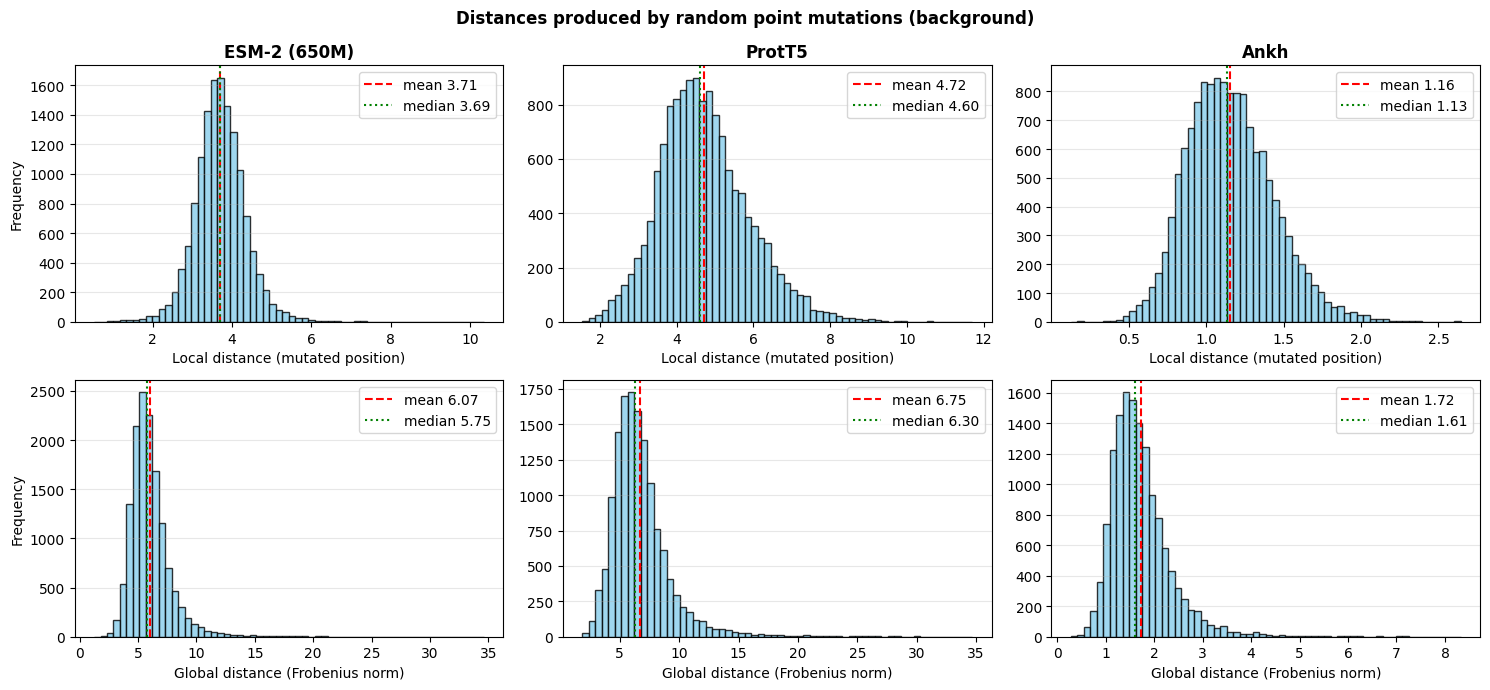

In [ ]:
MODELS = list(EMBEDDING_MODELS)
fig, axes = plt.subplots(2, len(MODELS), figsize=(5 * len(MODELS), 7))
for col, model_name in enumerate(MODELS):
    sub = df_background[df_background["embedding_model"] == model_name]
    for row, (value_col, label) in enumerate([("dist_local", "Local distance (mutated position)"),
                                              ("dist_global", "Global distance (Frobenius norm)")]):
        ax = axes[row, col]
        ax.hist(sub[value_col], bins=60, color="skyblue", edgecolor="black", alpha=0.8)
        ax.axvline(sub[value_col].mean(), color="red", linestyle="--", label=f"mean {sub[value_col].mean():.2f}")
        ax.axvline(sub[value_col].median(), color="green", linestyle=":", label=f"median {sub[value_col].median():.2f}")
        ax.set_title(model_name if row == 0 else "", fontweight="bold")
        ax.set_xlabel(label)
        ax.set_ylabel("Frequency" if col == 0 else "")
        ax.legend()
        ax.grid(axis="y", alpha=0.3)
plt.suptitle("Distances produced by random point mutations (background)", fontweight="bold")
plt.tight_layout()
save_figure("background_distribution_raw.png")
plt.show()

Relative distances (distance / norm of the WT embedding) can be compared across models.

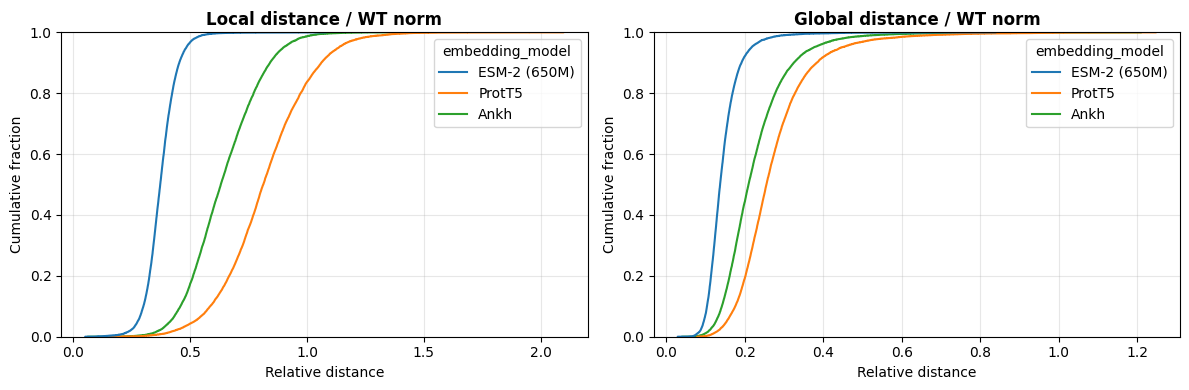

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, value_col, title in zip(axes, ["dist_local_rel", "dist_global_rel"],
                                ["Local distance / WT norm", "Global distance / WT norm"]):
    sns.ecdfplot(data=df_background, x=value_col, hue="embedding_model", hue_order=MODELS, ax=ax)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Relative distance")
    ax.set_ylabel("Cumulative fraction")
    ax.grid(alpha=0.3)
plt.tight_layout()
save_figure("background_distribution_relative.png")
plt.show()

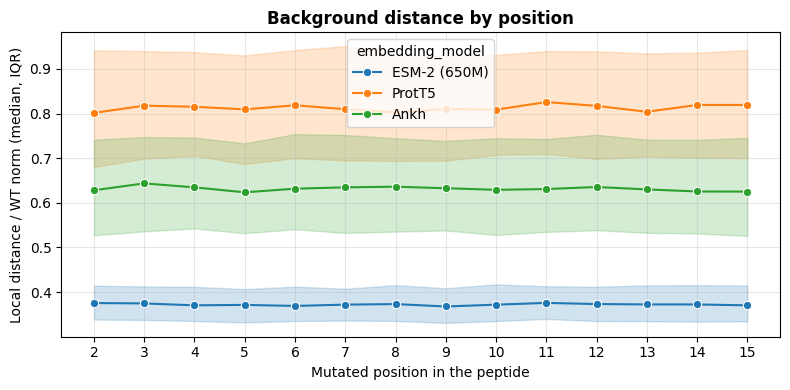

In [ ]:
plt.figure(figsize=(8, 4))
sns.lineplot(data=df_background, x="position", y="dist_local_rel", hue="embedding_model", hue_order=MODELS,
             estimator="median", errorbar=("pi", 50), marker="o")
plt.xticks(MUTATED_POSITIONS)
plt.xlabel("Mutated position in the peptide")
plt.ylabel("Local distance / WT norm (median, IQR)")
plt.title("Background distance by position", fontweight="bold")
plt.grid(alpha=0.3)
plt.tight_layout()
save_figure("background_by_position.png")
plt.show()

---
## Part B · Observed LxCxE mutations vs. the background  *(requires notebooks 01 and 03)*

Each observed distance (relative to the WT norm) is located in the background distribution of **the same model and
position** (percentile).

In [ ]:
observed_file = PROCESSED_DIR / "mutant_embedding_distances.csv"
if not observed_file.exists():
    raise FileNotFoundError("Part B needs the outputs of notebook 03 (mutant_embedding_distances.csv, "
                            "wt_embeddings.npz). Run notebook 03 first, or skip Part B.")

df_tp = pd.read_csv(PROCESSED_DIR / "df_tp.csv")
PROTEINS = df_tp["protein"].tolist()
df_distances = pd.read_csv(observed_file)
with np.load(PROCESSED_DIR / "wt_embeddings.npz") as archive:
    wt_embeddings = {tuple(key.split("__", 1)): archive[key] for key in archive.files}

observed = df_distances[["protein", "mutation", "position", "embedding_model",
                         "dist_local", "dist_global"]].copy()
observed["dist_local_rel"] = [
    d / np.linalg.norm(wt_embeddings[(p, m)][pos - 1])
    for d, p, m, pos in zip(observed["dist_local"], observed["protein"],
                            observed["embedding_model"], observed["position"])
]
observed["dist_global_rel"] = [
    d / np.linalg.norm(wt_embeddings[(p, m)])
    for d, p, m in zip(observed["dist_global"], observed["protein"], observed["embedding_model"])
]
observed["region"] = np.where(observed["position"].isin(CORE_POSITIONS), "core", "flanking")


def percentile_in_background(value_col):
    """Percentile (0-100) of each observed value in the background of its model and position."""
    result = np.full(len(observed), np.nan)
    for (model, position), idx in observed.groupby(["embedding_model", "position"]).groups.items():
        reference = np.sort(df_background.loc[
            (df_background["embedding_model"] == model) & (df_background["position"] == position),
            value_col].values)
        if len(reference) == 0:
            continue
        values = observed.loc[idx, value_col].values
        result[observed.index.get_indexer(idx)] = np.searchsorted(reference, values, side="right") / len(reference)
    return 100 * result


observed["pct_local"] = percentile_in_background("dist_local_rel")
observed["pct_global"] = percentile_in_background("dist_global_rel")

comparison = observed.groupby(["embedding_model", "region"]).agg(
    n=("mutation", "size"),
    local_rel_median=("dist_local_rel", "median"),
    local_median_percentile=("pct_local", "median"),
    local_pct_above_p95=("pct_local", lambda s: 100 * (s > 95).mean()),
    global_rel_median=("dist_global_rel", "median"),
    global_median_percentile=("pct_global", "median"),
    global_pct_above_p95=("pct_global", lambda s: 100 * (s > 95).mean()),
)
comparison.round(2).to_csv(RESULTS_DIR / "background_comparison.csv")
comparison.round(2)

n  local_rel_median  local_median_percentile  \
embedding_model region                                                      
Ankh            core       285              0.78                     82.1   
                flanking  1044              0.79                     82.4   
ESM-2 (650M)    core       285              0.35                     38.6   
                flanking  1044              0.37                     45.9   
ProtT5          core       285              0.96                     77.9   
                flanking  1044              0.98                     80.5   

                          local_pct_above_p95  global_rel_median  \
embedding_model region                                             
Ankh            core                    12.28               0.27   
                flanking                14.08               0.28   
ESM-2 (650M)    core                     3.51               0.13   
                flanking                 6.90               0.14   
ProtT5          core                    18.25               0.31   
                flanking                14.46               0.31   

                          global_median_percentile  global_pct_above_p95  
embedding_model region                                                    
Ankh            core                          77.2                 10.18  
                flanking                      80.3                 14.08  
ESM-2 (650M)    core                          42.1                  5.26  
                flanking                      49.9                  7.57  
ProtT5          core                          73.0                  9.47  
                flanking                      76.5                  8.43

/tmp/ipykernel_369/1039644560.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=data, x="group", y=value_col, col="embedding_model", col_order=MODELS,


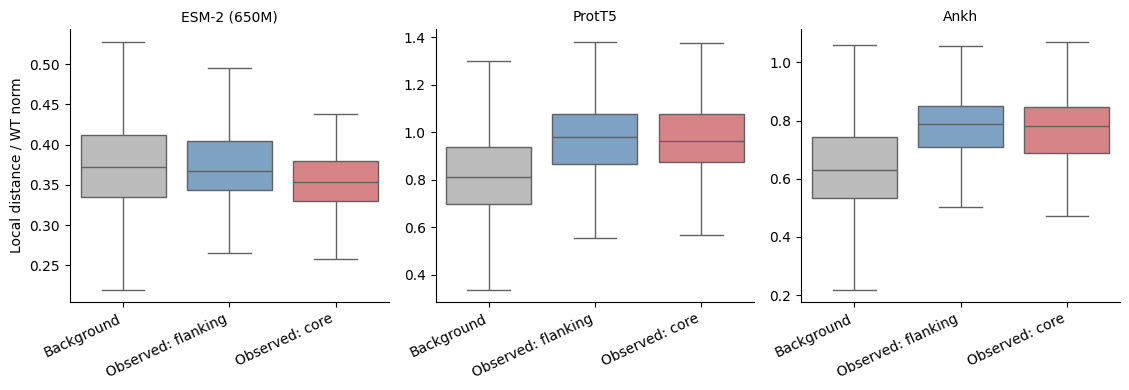

/tmp/ipykernel_369/1039644560.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(data=data, x="group", y=value_col, col="embedding_model", col_order=MODELS,


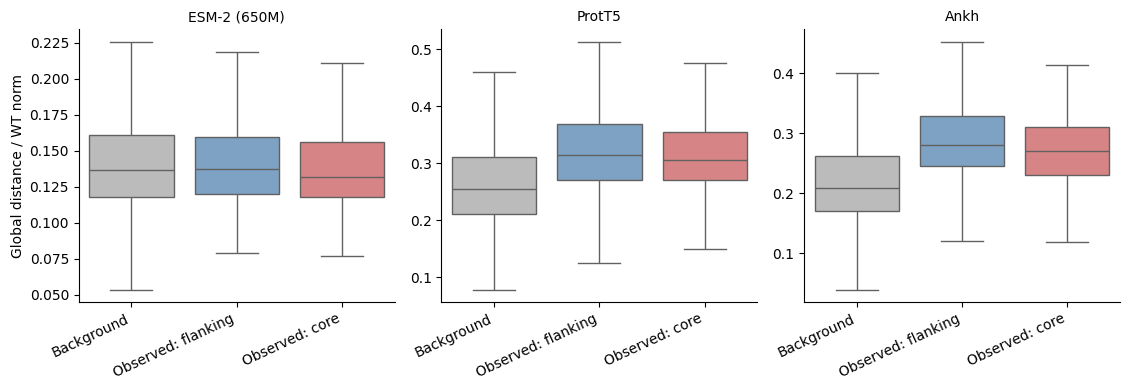

In [ ]:
def plot_background_comparison(value_col, ylabel, file_name):
    data = pd.concat([
        df_background.assign(group="Background")[["embedding_model", value_col, "group"]],
        observed.assign(group=np.where(observed["region"] == "core", "Observed: core", "Observed: flanking"))[
            ["embedding_model", value_col, "group"]],
    ], ignore_index=True)
    g = sns.catplot(data=data, x="group", y=value_col, col="embedding_model", col_order=MODELS,
                    order=["Background", "Observed: flanking", "Observed: core"], kind="box",
                    sharey=False, showfliers=False, height=4, aspect=0.95,
                    palette=["#bbbbbb", "#72a3d0", "#e37778"])
    g.set_axis_labels("", ylabel)
    g.set_titles("{col_name}")
    for ax in g.axes.flat:
        ax.tick_params(axis="x", rotation=25)
        for label in ax.get_xticklabels():
            label.set_ha("right")
    plt.tight_layout()
    save_figure(file_name)
    plt.show()


plot_background_comparison("dist_local_rel", "Local distance / WT norm", "background_vs_observed_local.png")
plot_background_comparison("dist_global_rel", "Global distance / WT norm", "background_vs_observed_global.png")

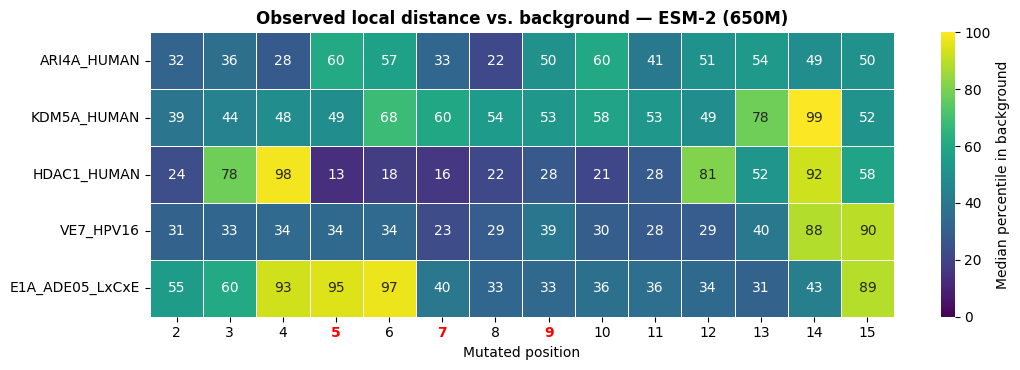

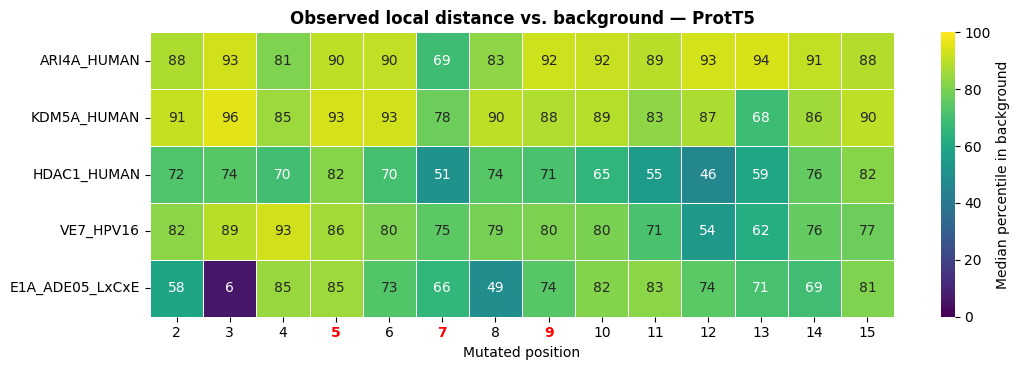

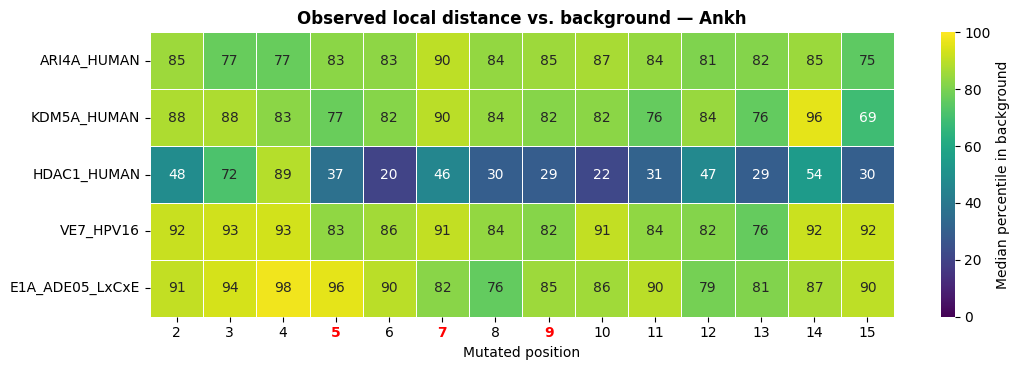

In [ ]:
def plot_percentile_heatmap(model_name, value_col="pct_local", save=True):
    sub = observed[observed["embedding_model"] == model_name]
    table = sub.pivot_table(index="protein", columns="position", values=value_col,
                            aggfunc="median").reindex(PROTEINS)
    plt.figure(figsize=(11, 3.8))
    ax = sns.heatmap(table, cmap="viridis", vmin=0, vmax=100, annot=True, fmt=".0f",
                     linewidths=0.5, cbar_kws={"label": "Median percentile in background"})
    for tick, position in zip(ax.get_xticklabels(), table.columns):
        if position in CORE_POSITIONS:
            tick.set_color("red")
            tick.set_fontweight("bold")
    kind = "local" if value_col == "pct_local" else "global"
    ax.set_xlabel("Mutated position")
    ax.set_ylabel("")
    plt.title(f"Observed {kind} distance vs. background — {model_name}", fontweight="bold")
    plt.tight_layout()
    if save:
        slug = model_name.split(" ")[0].lower().replace("-", "")
        save_figure(f"background_percentile_{kind}_{slug}.png")
    plt.show()


for model_name in MODELS:
    plot_percentile_heatmap(model_name, "pct_local")